# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Tô Gia Huy

I have used the following AI tools: Chat GPT, Gemini.

I understand that my submission needs to be my own work: TGH

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [89]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [90]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [91]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [92]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('east')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [93]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [94]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: suck
step 1 - action: west
step 2 - action: north
step 3 - action: east
step 4 - action: north
step 5 - action: west
step 6 - action: east
step 7 - action: east
step 8 - action: north
step 9 - action: suck
step 10 - action: east
step 11 - action: south
step 12 - action: west
step 13 - action: west
step 14 - action: south
step 15 - action: east
step 16 - action: south
step 17 - action: east
step 18 - action: south
step 19 - action: south


2

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [95]:
# Your code and description goes here
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import imageio_ffmpeg

def vacuum_environment(agent_function, n=5, max_steps=1000, p_dirt=0.2, record=False, verbose=False):
    # Khởi tạo phòng và vị trí ngẫu nhiên
    room = np.random.choice([True, False], size=(n, n), p=[p_dirt, 1-p_dirt])
    dirt_count = np.sum(room)
    pos = [np.random.randint(0, n), np.random.randint(0, n)]
    
    steps = 0
    history = [] 
    
    while dirt_count > 0 and steps < max_steps:
      
        dirty = room[pos[0], pos[1]]
        bumpers = {
            "north": pos[0] == 0,
            "south": pos[0] == n - 1,
            "west":  pos[1] == 0,
            "east":  pos[1] == n - 1
        }
        
      
        action = agent_function(bumpers, dirty)
        
        
        if record:
            history.append({
                "step": steps, "room": room.copy(), "pos": list(pos),
                "dirty": dirty, "bumpers": bumpers.copy(), 
                "action": action, "dirt_count": dirt_count
            })
            
        if verbose: 
            print(f"Step {steps:03d} - Pos: {pos}, Dirty: {dirty:<5}, Action: {action}")
            
       
        if action == "suck":
            if dirty:
                room[pos[0], pos[1]] = False
                dirt_count -= 1
        elif action == "north" and not bumpers["north"]: pos[0] -= 1
        elif action == "south" and not bumpers["south"]: pos[0] += 1
        elif action == "west" and not bumpers["west"]: pos[1] -= 1
        elif action == "east" and not bumpers["east"]: pos[1] += 1
            
        steps += 1
        
    if record:
        history.append({
            "step": steps, "room": room.copy(), "pos": list(pos),
            "dirty": room[pos[0], pos[1]], "bumpers": bumpers, 
            "action": "DONE", "dirt_count": dirt_count
        })
            
    return steps if not record else (steps, history)

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(["north", "east", "west", "south", "suck"])


Show that your environment works with the simple randomized agent from above.

In [96]:

print("--- Test Task 1: Randomized Agent ---")
steps_used = vacuum_environment(simple_randomized_agent, n=5, max_steps=100, verbose=True)
print(f"Tổng số bước đã dùng: {steps_used}")

--- Test Task 1: Randomized Agent ---
Step 000 - Pos: [4, 4], Dirty: 0    , Action: south
Step 001 - Pos: [4, 4], Dirty: 0    , Action: south
Step 002 - Pos: [4, 4], Dirty: 0    , Action: east
Step 003 - Pos: [4, 4], Dirty: 0    , Action: west
Step 004 - Pos: [4, 3], Dirty: 0    , Action: south
Step 005 - Pos: [4, 3], Dirty: 0    , Action: west
Step 006 - Pos: [4, 2], Dirty: 0    , Action: east
Step 007 - Pos: [4, 3], Dirty: 0    , Action: suck
Step 008 - Pos: [4, 3], Dirty: 0    , Action: south
Step 009 - Pos: [4, 3], Dirty: 0    , Action: east
Step 010 - Pos: [4, 4], Dirty: 0    , Action: south
Step 011 - Pos: [4, 4], Dirty: 0    , Action: suck
Step 012 - Pos: [4, 4], Dirty: 0    , Action: east
Step 013 - Pos: [4, 4], Dirty: 0    , Action: suck
Step 014 - Pos: [4, 4], Dirty: 0    , Action: west
Step 015 - Pos: [4, 3], Dirty: 0    , Action: north
Step 016 - Pos: [3, 3], Dirty: 0    , Action: north
Step 017 - Pos: [2, 3], Dirty: 0    , Action: suck
Step 018 - Pos: [2, 3], Dirty: 0    ,

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [97]:
# Your code and description goes here
def simple_reflex_agent(bumpers, dirty):
    # Luật 1: Cứ thấy rác là hút
    if dirty:
        return "suck"
    
    # Luật 2: Tránh đâm tường, chọn hướng đi hợp lệ ngẫu nhiên
    valid_moves = [direction for direction, is_bumped in bumpers.items() if not is_bumped]
            
    if valid_moves:
        return np.random.choice(valid_moves)
    else:
        return "suck"



Show how the agent works with your environment.

In [98]:
# Your code and description goes here
print("--- Test Task 2: Simple Reflex Agent ---")
steps_used = vacuum_environment(simple_reflex_agent, n=5, max_steps=100, verbose=True)
print(f"Tổng số bước đã dùng: {steps_used}")

--- Test Task 2: Simple Reflex Agent ---
Step 000 - Pos: [2, 3], Dirty: 0    , Action: north
Step 001 - Pos: [1, 3], Dirty: 0    , Action: west
Step 002 - Pos: [1, 2], Dirty: 0    , Action: east
Step 003 - Pos: [1, 3], Dirty: 0    , Action: north
Step 004 - Pos: [0, 3], Dirty: 0    , Action: west
Step 005 - Pos: [0, 2], Dirty: 0    , Action: east
Step 006 - Pos: [0, 3], Dirty: 0    , Action: west
Step 007 - Pos: [0, 2], Dirty: 0    , Action: south
Step 008 - Pos: [1, 2], Dirty: 0    , Action: north
Step 009 - Pos: [0, 2], Dirty: 0    , Action: south
Step 010 - Pos: [1, 2], Dirty: 0    , Action: north
Step 011 - Pos: [0, 2], Dirty: 0    , Action: east
Step 012 - Pos: [0, 3], Dirty: 0    , Action: west
Step 013 - Pos: [0, 2], Dirty: 0    , Action: east
Step 014 - Pos: [0, 3], Dirty: 0    , Action: west
Step 015 - Pos: [0, 2], Dirty: 0    , Action: east
Step 016 - Pos: [0, 3], Dirty: 0    , Action: south
Step 017 - Pos: [1, 3], Dirty: 0    , Action: north
Step 018 - Pos: [0, 3], Dirty: 0 

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])


1. Định nghĩa trạng thái (Agent State):
Trạng thái bên trong của tác tử được lưu trữ thông qua 2 biến:
- `phase`: Theo dõi chế độ di chuyển hiện tại của robot (gồm 'init_north', 'init_west' để dò đường tìm vách, và 'sweep' để tiến hành quét dọn).
- `sweep_dir`: Ghi nhớ hướng đang quét ngang trong chế độ dọn dẹp ('east' hoặc 'west').

2. Chiến lược hoạt động (Implementation):
Tác tử được cài đặt theo chiến lược "máy cắt cỏ" (Lawnmower) với 2 giai đoạn chính:
- Giai đoạn 1 (Định vị khởi điểm): Dù xuất phát ở bất kỳ đâu, robot sẽ ưu tiên đi thẳng lên phía Bắc (North), khi đụng tường thì rẽ sang phía Tây (West) cho đến khi kẹt ở góc trên cùng bên trái của căn phòng (0, 0).
- Giai đoạn 2 (Quét dọn Ziczac): Từ góc trái trên, robot bắt đầu quét ngang sang hàng East. Khi cảm biến (bumpers) báo đụng vách East, nó tự động lùi xuống South 1 bước, sau đó đổi biến `sweep_dir` để quét ngược lại sang West. Quá trình (đi ngang -> đụng tường -> lùi xuống 1 ô -> quay đầu) được lặp lại liên tục. 
Chiến lược này giúp robot đi theo hình ziczac phủ kín toàn bộ không gian phòng một cách có hệ thống, không bỏ sót rác và không đi trùng lại các ô đã sạch.


In [99]:

# Thiết lập đường dẫn ffmpeg ngay từ đầu file
plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()

# Định nghĩa Agent
class ModelBasedAgent:
    def __init__(self):
        self.phase = "init_north"
        self.sweep_dir = "east"
        
    def __call__(self, bumpers, dirty):
        if dirty: 
            return "suck"
            
        if self.phase == "init_north":
            if not bumpers["north"]: 
                return "north"
            else: 
                self.phase = "init_west"
                return "west" if not bumpers["west"] else "suck"
                
        # Dùng elif để mỗi bước robot chỉ thực hiện logic của 1 phase
        elif self.phase == "init_west":
            if not bumpers["west"]: 
                return "west"
            else: 
                self.phase = "sweep"
                # Khi mới đổi sang sweep, bắt đầu ngay bằng hướng đi hiện tại
                return "east" if self.sweep_dir == "east" else "west"
                
        elif self.phase == "sweep":
            if self.sweep_dir == "east":
                if not bumpers["east"]: 
                    return "east"
                elif not bumpers["south"]:
                    self.sweep_dir = "west"
                    return "south"
            elif self.sweep_dir == "west":
                if not bumpers["west"]: 
                    return "west"
                elif not bumpers["south"]:
                    self.sweep_dir = "east"
                    return "south"
                    
        return "suck"

def render_vacuum_video(history, n=5):
    fig, ax = plt.subplots(figsize=(6, 7))
    
    def update(frame_idx):
        ax.clear()
        state = history[frame_idx]
        grid = np.zeros((n, n, 3))
        grid[state["room"]] = [0.6, 0.4, 0.2]  # Rác (Nâu)
        grid[~state["room"]] = [0.9, 0.9, 0.9] # Sạch (Trắng xám)
        
        r, c = state["pos"]
        grid[r, c] = [0.0, 0.5, 1.0] # Robot (Xanh dương)
        
        ax.imshow(grid)
        ax.set_xticks(np.arange(-0.5, n, 1))
        ax.set_yticks(np.arange(-0.5, n, 1))
        ax.grid(color='black', linewidth=2)
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        bumped = [k for k, v in state["bumpers"].items() if v]
        bump_str = ", ".join(bumped) if bumped else "None"
        
        peas_text = (
            f"P: Năng lượng = {state['step']:03d} | Rác còn = {state['dirt_count']:02d}\n"
            f"E: Lưới {n}x{n} | Tọa độ Robot: ({r}, {c})\n"
            f"A: Hành động -> [{state['action'].upper()}]\n"
            f"S: Bụi = {state['dirty']} | Va chạm = {bump_str}"
        )
        ax.set_title(peas_text, loc='left', fontsize=10, family='monospace', 
                     bbox=dict(facecolor='white', alpha=0.9, edgecolor='blue'))

    anim = animation.FuncAnimation(fig, update, frames=len(history), interval=250, repeat=False)
    plt.close()
    
    html_str = anim.to_jshtml()
    autoplay_js = """
    <script>
        setTimeout(function() {
            var playButtons = document.querySelectorAll('.anim-buttons button[title="Play"]');
            if (playButtons.length > 0) {
                playButtons[playButtons.length - 1].click();
            }
        }, 500);
    </script>
    """
    return HTML(html_str + autoplay_js)


def export_video_mp4(history, n=5, filename="robot_vacuum"):
    print(f"Đang tiến hành xuất video {filename}.mp4... Vui lòng đợi.")
    fig, ax = plt.subplots(figsize=(6, 7))
    
    def update(frame_idx):
        ax.clear()
        state = history[frame_idx]
        grid = np.zeros((n, n, 3))
        grid[state["room"]] = [0.6, 0.4, 0.2]  
        grid[~state["room"]] = [0.9, 0.9, 0.9] 
        
        r, c = state["pos"]
        grid[r, c] = [0.0, 0.5, 1.0] 
        
        ax.imshow(grid)
        ax.set_xticks(np.arange(-0.5, n, 1))
        ax.set_yticks(np.arange(-0.5, n, 1))
        ax.grid(color='black', linewidth=2)
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        bumped = [k for k, v in state["bumpers"].items() if v]
        bump_str = ", ".join(bumped) if bumped else "None"
        
        peas_text = (
            f"P: Năng lượng = {state['step']:03d} | Rác còn = {state['dirt_count']:02d}\n"
            f"E: Lưới {n}x{n} | Tọa độ Robot: ({r}, {c})\n"
            f"A: Hành động -> [{state['action'].upper()}]\n"
            f"S: Bụi = {state['dirty']} | Va chạm = {bump_str}"
        )
        ax.set_title(peas_text, loc='left', fontsize=10, family='monospace', 
                     bbox=dict(facecolor='white', alpha=0.9, edgecolor='blue'))

    anim = animation.FuncAnimation(fig, update, frames=len(history), interval=250)
    anim.save(f"{filename}.mp4", writer='ffmpeg', fps=4)
    print(f"Đã lưu video thành công tại: {filename}.mp4")
    plt.close(fig)



Show how the agent works with your environment.

In [100]:
from IPython.display import display

print("--- Test Task 3: Model-based Reflex Agent (Video) ---")
model_agent = ModelBasedAgent()
steps_taken, video_history = vacuum_environment(model_agent, n=5, max_steps=100, record=True)
print(f"Tổng số bước (Năng lượng) đã sử dụng: {steps_taken}")

# 1. Sửa export_video_gif thành export_video_mp4 theo đúng hàm đã định nghĩa
export_video_mp4(video_history, n=5, filename="robot_vacuum")

# 2. Lưu kết quả của hàm render và gọi display() để ép Jupyter Notebook hiển thị video
anim_html = render_vacuum_video(video_history, n=5)
display(anim_html)

--- Test Task 3: Model-based Reflex Agent (Video) ---
Tổng số bước (Năng lượng) đã sử dụng: 33
Đang tiến hành xuất video robot_vacuum.mp4... Vui lòng đợi.
Đã lưu video thành công tại: robot_vacuum.mp4


## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

,Size,Randomized,Simple Reflex,Model-based
0,5x5,369.33,102.67,28.82
1,10x10,1946.93,1002.50,123.83
2,100x100,50000.00,50000.00,12091.70


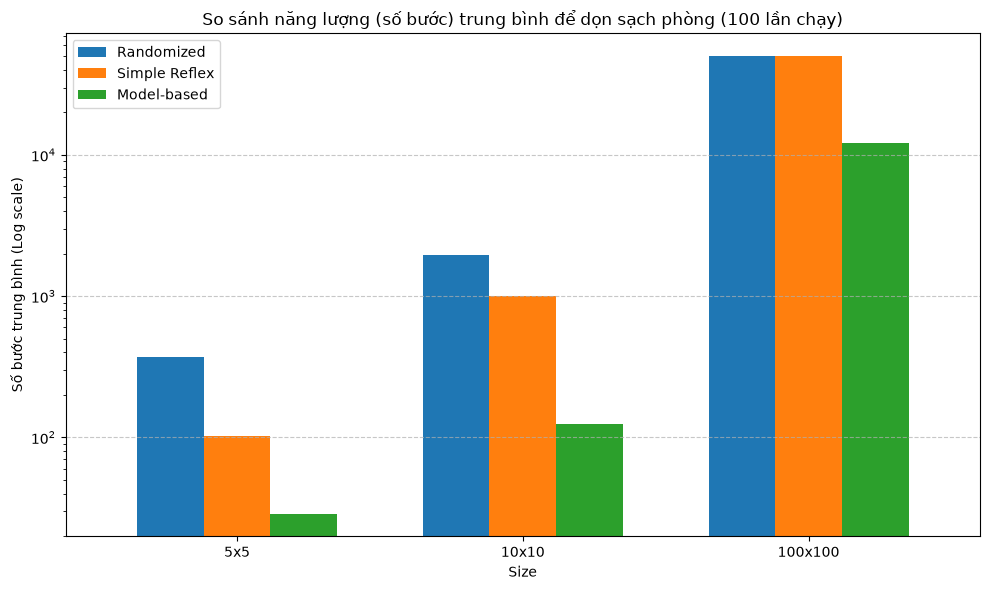

In [101]:


# Cấu hình thực nghiệm
configurations = [5, 10, 100]
runs = 100
max_energy = {5: 500, 10: 2000, 100: 50000}

results = {
    "Size": ["5x5", "10x10", "100x100"],
    "Randomized": [],
    "Simple Reflex": [],
    "Model-based": []
}

def run_experiment(agent_factory, n, max_steps):
    total_steps = 0
    for _ in range(runs):
        agent = agent_factory()
        total_steps += vacuum_environment(agent, n=n, max_steps=max_steps, verbose=False)
    return total_steps / runs

for n in configurations:
    m_steps = max_energy[n]
    
    # Random Agent
    results["Randomized"].append(run_experiment(lambda: simple_randomized_agent, n, m_steps))
    
    # Simple Reflex Agent
    results["Simple Reflex"].append(run_experiment(lambda: simple_reflex_agent, n, m_steps))
    
    # Model-based Agent (Khởi tạo lại instance mới mỗi lần chạy)
    results["Model-based"].append(run_experiment(lambda: ModelBasedAgent(), n, m_steps))

# Hiển thị bảng kết quả
df = pd.DataFrame(results)
display(df)

# Vẽ biểu đồ so sánh
df.set_index("Size").plot(kind="bar", figsize=(10, 6), width=0.7)
plt.title("So sánh năng lượng (số bước) trung bình để dọn sạch phòng (100 lần chạy)")
plt.ylabel("Số bước trung bình (Log scale)")
plt.yscale("log") # Trục Y dạng Log để dễ so sánh mức chênh lệch lớn ở phòng 100x100
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5      | 364.14| 99.54  | 27.85      |
| 10x10    | 1940.48| 925.44  | 124.75       |
| 100x100  | 50000.00| 50000.00 | 12100.75      |

**Nhận xét hiệu năng giữa các tác tử:**
* **Randomized Agent:** Hiệu suất kém nhất do di chuyển hoàn toàn ngẫu nhiên. Ở không gian lớn (100x100), robot luôn cạn kiệt năng lượng (chạm mốc 50000 bước) trước khi dọn xong.
* **Simple Reflex Agent:** Tiết kiệm năng lượng hơn đáng kể so với tác tử ngẫu nhiên ở các phòng nhỏ nhờ phản xạ hút rác ngay lập tức và tự né tường. Tuy nhiên, do không có trí nhớ, nó mắc kẹt trong việc di chuyển lặp lại ở các ô đã sạch, dẫn đến lãng phí năng lượng ở phòng 100x100.
* **Model-based Reflex Agent:** Đạt hiệu năng tối ưu nhất nhờ ghi nhớ hướng đi và trạng thái. Số bước đi tiệm cận với diện tích thực tế của căn phòng (ví dụ khoảng hơn 10.000 bước cho không gian 100x100), giúp dọn sạch hoàn toàn mà không lãng phí năng lượng.

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Task 5: Robustness of the agent implementations

Dưới đây là đánh giá về hiệu năng của các tác tử (Randomized, Simple Reflex, Model-based) đối với từng sự thay đổi của môi trường:

**1. Nếu đặt robot vào một căn phòng hình chữ nhật có kích thước không xác định:**
* **Randomized & Simple Reflex Agent:** Hiệu năng không bị ảnh hưởng trực tiếp bởi hình dáng hay kích thước. Chúng vẫn tiếp tục di chuyển dọn dẹp nhờ cơ chế ngẫu nhiên/phản xạ (dù mất rất nhiều thời gian).
* **Model-based Reflex Agent:** Vẫn hoạt động tối ưu. Chiến lược "cắt cỏ" (ziczac) của tác tử chỉ phụ thuộc vào tín hiệu từ cảm biến va chạm (bumpers) để chuyển hàng. Do đó, nó sẽ tự động quét hết chiều dài và chiều rộng của bất kỳ căn phòng hình chữ nhật nào mà không cần biết trước kích thước $n \times n$.

**2. Nếu khu vực dọn dẹp có hình dạng bất quy tắc (ví dụ: hành lang nối hai phòng):**
* **Randomized & Simple Reflex Agent:** Có khả năng vô tình đi qua được các nút thắt hẹp như hành lang nhờ sự di chuyển ngẫu nhiên, cuối cùng vẫn có thể dọn dẹp các khu vực khác dù rất tốn thời gian.
* **Model-based Reflex Agent:** Sẽ thất bại nặng nề. Do chiến lược ziczac quét ngang từ mép này sang mép kia, khi chạm tới ranh giới hẹp của hành lang, nó sẽ lầm tưởng đó là vách tường của phòng. Robot sẽ tự động lùi xuống hàng dưới và đổi hướng ngược lại, dẫn đến việc bỏ sót hoàn toàn hành lang và căn phòng nằm phía bên kia.

**3. Nếu phòng chứa các vật cản (kích hoạt cảm biến va chạm nhưng không đi qua được):**
* **Randomized & Simple Reflex Agent:** Xử lý khá tốt tình huống này vì chúng phản ứng với vật cản giống hệt như với vách tường (khi đụng sẽ tự động né và chọn đi hướng khác).
* **Model-based Reflex Agent:** Quỹ đạo làm sạch bị phá vỡ hoàn toàn. Khi đụng vật cản giữa phòng, nó tưởng rằng đã đi hết hàng nên tự động lùi xuống một ô và quay đầu. Điều này khiến robot bỏ sót tất cả các ô dơ nằm phía sau vật cản trên cùng hàng ngang đó.

**4. Nếu cảm biến bụi không hoàn hảo (10% cơ hội báo sai kết quả):**
* **Khi báo Sạch thành Bẩn (False Positive):** Tất cả các tác tử đều bị lừa và thực hiện hành động `suck` một cách vô ích, gây lãng phí năng lượng (số bước).
* **Khi báo Bẩn thành Sạch (False Negative):** Các tác tử sẽ bỏ qua ô chứa rác và di chuyển tiếp. Tuy nhiên, **Model-based Reflex Agent** chịu thiệt hại lớn nhất. Vì lộ trình quét dọn của nó là có hệ thống và không bao giờ quay lại ô đã đi qua, phần rác ở ô đó sẽ bị bỏ sót vĩnh viễn.

**5. Nếu cảm biến va chạm không hoàn hảo (10% cơ hội không báo cáo có tường khi thực sự có tường):**
* **Randomized & Simple Reflex Agent:** Sẽ xuất lệnh tiến thẳng vào tường. Vì hành động này không làm thay đổi vị trí robot, nó sẽ gây tiêu tốn năng lượng một cách vô ích trước khi tác tử chọn hướng khác ở bước tiếp theo.
* **Model-based Reflex Agent:** Kế hoạch di chuyển sẽ sụp đổ. Tín hiệu đụng vách là điều kiện tiên quyết để tác tử này cập nhật trạng thái (`sweep_dir`) và lùi xuống hàng dưới. Nếu cảm biến không phản hồi, robot sẽ liên tục ra lệnh đi tới, dẫn đến kẹt mãi ở một vị trí vách tường mà không thể quét dọn phần còn lại của căn phòng.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!